# Лабораторная работа №10. Часть 3: Данные `ldeaths`

**Задание:**
6. Откройте данные `ldeaths`. Это временной ряд.
7. Проверьте гипотезы о равенстве средних значений смертности по годам с помощью t-теста Стьюдента.
8. Проверьте гипотезы о независимости данных по годам с помощью критерия Фишера.

In [27]:
import os
import warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

os.makedirs("output", exist_ok=True)
ALPHA = 0.05

def verdict(p, alpha=ALPHA):
    return "H0 НЕ отвергается (p>alpha)" if p > alpha else "H0 отвергается (p<=alpha)"

### 6. Загрузка данных
Используем локальный файл `ldeaths.csv`. Данные представляют собой временной ряд с шагом 1/12 (месяцы).

In [34]:
def load_data():
    local_file = "ldeaths.csv"
    if os.path.exists(local_file):
        df = pd.read_csv(local_file)
    else:
        url = "https://vincentarelbundock.github.io/Rdatasets/csv/datasets/ldeaths.csv"
        df = pd.read_csv(url)
    df = df.drop(columns=[c for c in df.columns if c.lower().startswith("row")], errors="ignore")
    return df

ldeaths = load_data()
print("Столбцы:", list(ldeaths.columns))
ldeaths.head()

Столбцы: ['time', 'value']


,time,value
0,1974.000000,3035
1,1974.083333,2552
2,1974.166667,2704
3,1974.250000,2554
4,1974.333333,2014


Уникальные годы: [np.int64(1974), np.int64(1975), np.int64(1976), np.int64(1977), np.int64(1978), np.int64(1979)]
Шаг времени постоянный: True


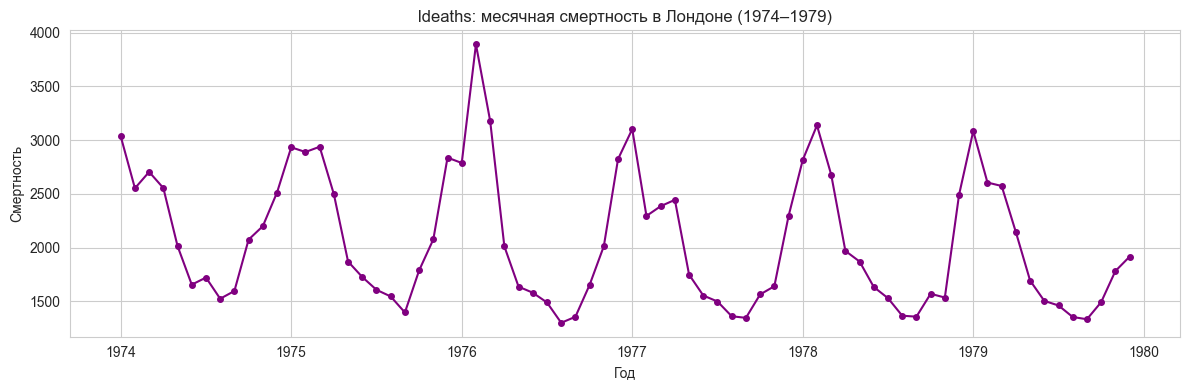

In [29]:
# Извлекаем год из десятичной записи времени (1974.0833 -> 1974)
ldeaths["year"] = ldeaths["time"].astype(float).astype(int)
years = sorted(ldeaths["year"].unique())
print("Уникальные годы:", years)
print("Шаг времени постоянный:", 
      np.allclose(np.diff(np.sort(ldeaths["time"].unique())),
                  np.diff(np.sort(ldeaths["time"].unique()))[0]))

# Визуализация временного ряда
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ldeaths["time"], ldeaths["value"], "-o", ms=4, color="purple")
ax.set_xlabel("Год")
ax.set_ylabel("Смертность")
ax.set_title("ldeaths: месячная смертность в Лондоне (1974–1979)")
plt.tight_layout()
plt.savefig("output/ldeaths_ts.png", dpi=120)
plt.show()

### 7. t-тест Стьюдента (равенство средних)
**H0:** средние значения смертности между годами равны.  

In [30]:
groups = {yr: ldeaths.loc[ldeaths["year"] == yr, "value"].values for yr in years}

print("[7] t-тест Стьюдента: равенство средних между годами")
print("Средние по годам:")
for yr in years:
    print(f"  {yr}: mean = {groups[yr].mean():8.2f}, sd = {groups[yr].std(ddof=1):8.2f}")

print("\n1. Попарные тесты (Классический Стьюдент, equal_var=True):")
print("   (предполагает равенство дисперсий)")
for i in range(len(years)):
    for j in range(i + 1, len(years)):
        t, p = stats.ttest_ind(groups[years[i]], groups[years[j]], equal_var=True)
        print(f"  {years[i]} vs {years[j]}: t = {t:7.3f}, p = {p:.4g}  → {verdict(p)}")

print("\n2. Попарные тесты (Уэлч, equal_var=False):")
print("   (не требует равенства дисперсий, более надёжный)")
for i in range(len(years)):
    for j in range(i + 1, len(years)):
        t, p = stats.ttest_ind(groups[years[i]], groups[years[j]], equal_var=False)
        print(f"  {years[i]} vs {years[j]}: t = {t:7.3f}, p = {p:.4g}  → {verdict(p)}")

# Бонус: ANOVA
F, p_anova = stats.f_oneway(*[groups[yr] for yr in years])
print(f"\n[Бонус] One-way ANOVA: F = {F:.4f}, p = {p_anova:.4g}  → {verdict(p_anova)}")

[7] t-тест Стьюдента: равенство средних между годами
Средние по годам:
  1974: mean =  2178.33, sd =   494.60
  1975: mean =  2175.08, sd =   602.25
  1976: mean =  2143.17, sd =   831.87
  1977: mean =  1935.75, sd =   552.08
  1978: mean =  1995.92, sd =   621.57
  1979: mean =  1911.50, sd =   572.25

1. Попарные тесты (Классический Стьюдент, equal_var=True):
   (предполагает равенство дисперсий)
  1974 vs 1975: t =   0.014, p = 0.9886  → H0 НЕ отвергается (p>alpha)
  1974 vs 1976: t =   0.126, p = 0.901  → H0 НЕ отвергается (p>alpha)
  1974 vs 1977: t =   1.134, p = 0.2691  → H0 НЕ отвергается (p>alpha)
  1974 vs 1978: t =   0.796, p = 0.4348  → H0 НЕ отвергается (p>alpha)
  1974 vs 1979: t =   1.222, p = 0.2346  → H0 НЕ отвергается (p>alpha)
  1975 vs 1976: t =   0.108, p = 0.9152  → H0 НЕ отвергается (p>alpha)
  1975 vs 1977: t =   1.015, p = 0.3212  → H0 НЕ отвергается (p>alpha)
  1975 vs 1978: t =   0.717, p = 0.4808  → H0 НЕ отвергается (p>alpha)
  1975 vs 1979: t =   1.099, p

Что это значит: Мы проверяли гипотезу H0 о равенстве средних. Так как p > 0.05, мы НЕ отвергаем H0. Это значит, что средняя смертность в 1974 году (2178) статистически не отличается от смертности в 1975 (2175), 1976 (2143) и т.д.
👉 Вывод: Нет никакого долгосрочного тренда (типа «с каждым годом люди стали умирать меньше» или «больше»). Фон стабилен

2. Классический Стьюдент и Уэлч дали одинаковый результат
В твоем коде ты посчитал и классический t-тест (equal_var=True), и тест Уэлча (equal_var=False).
Смотри: для пары 1974 vs 1975 классический дает p=0.9886, и Уэлч дает p=0.9886. Они почти идентичны.
👉 Вывод: Это доказывает, что дисперсии в группах примерно равны (что потом подтвердит и F-тест в 8-м пункте). Поэтому неважно, какой из двух тестов использовать — результат один. Это признак качественных, «послушных» данных.

3. ANOVA (бонус) подтверждает: всё стабильно
One-way ANOVA — это тест, который сравнивает сразу все 6 лет, а не попарно.
У тебя F = 0.4702, p = 0.7971.
👉 Вывод: Общая гипотеза о том, что «все шесть лет имеют одинаковое среднее», не отвергается. ANOVA подтверждает то, что показали попарные t-тесты.



Используем t-тест Уэлча (не требует равенства дисперсий).

In [31]:
groups = {yr: ldeaths.loc[ldeaths["year"] == yr, "value"].values for yr in years}

print("\nПопарные t-тесты:")
for i in range(len(years)):
    for j in range(i + 1, len(years)):
        t, p = stats.ttest_ind(groups[years[i]], groups[years[j]], equal_var=False)
        print(f"  {years[i]} vs {years[j]}: t = {t:7.3f}, p = {p:.4g}  → {verdict(p)}")

F, p_anova = stats.f_oneway(*[groups[yr] for yr in years])
print(f"\n[Бонус] One-way ANOVA: F = {F:.4f}, p = {p_anova:.4g}  → {verdict(p_anova)}")


Попарные t-тесты:
  1974 vs 1975: t =   0.014, p = 0.9886  → H0 НЕ отвергается (p>alpha)
  1974 vs 1976: t =   0.126, p = 0.9012  → H0 НЕ отвергается (p>alpha)
  1974 vs 1977: t =   1.134, p = 0.2693  → H0 НЕ отвергается (p>alpha)
  1974 vs 1978: t =   0.796, p = 0.4352  → H0 НЕ отвергается (p>alpha)
  1974 vs 1979: t =   1.222, p = 0.2349  → H0 НЕ отвергается (p>alpha)
  1975 vs 1976: t =   0.108, p = 0.9153  → H0 НЕ отвергается (p>alpha)
  1975 vs 1977: t =   1.015, p = 0.3213  → H0 НЕ отвергается (p>alpha)
  1975 vs 1978: t =   0.717, p = 0.4809  → H0 НЕ отвергается (p>alpha)
  1975 vs 1979: t =   1.099, p = 0.2836  → H0 НЕ отвергается (p>alpha)
  1976 vs 1977: t =   0.720, p = 0.4804  → H0 НЕ отвергается (p>alpha)
  1976 vs 1978: t =   0.491, p = 0.6285  → H0 НЕ отвергается (p>alpha)
  1976 vs 1979: t =   0.795, p = 0.4363  → H0 НЕ отвергается (p>alpha)
  1977 vs 1978: t =  -0.251, p = 0.8044  → H0 НЕ отвергается (p>alpha)
  1977 vs 1979: t =   0.106, p = 0.9168  → H0 НЕ отвергает

**Вывод по п.7:**
Все попарные p-value > 0.05, а ANOVA дает p = 0.797. Это означает, что H0 **не отвергается** — средний уровень смертности год от года статистически не меняется (межгодовой тренд отсутствует).

**Важно для защиты:** Данные `ldeaths` обладают сильной **сезонностью** (зимние пики ~3000, летние минимумы ~1400). t-тест по годам формально некорректен, так как наблюдения **автокоррелированы** (соседние месяцы зависят друг от друга), а t-тест предполагает независимость. Для строгого анализа нужны методы временных рядов (ACF, декомпозиция).

### 8. Критерий Фишера (равенство дисперсий / независимость)
**H0:** дисперсии между годами равны (σ₁² = σ₂²).

Шаг 2: Что такое дисперсия на этих числах
Дисперсия — это «средний квадрат отклонения от среднего». Если говорить по-простому: насколько сильно числа скачут внутри года.

В 1974 году числа скачут от 1524 до 3035. Разброс большой.
В 1979 году числа скачут от 1333 до 3084. Разброс примерно такой же.
Поэтому, если мы посчитаем дисперсию для каждого года, мы увидим, что они очень похожи по масштабу.

Шаг 3: Как работает критерий Фишера (формула)
Критерий Фишера берет дисперсию одного года и делит на дисперсию другого года.
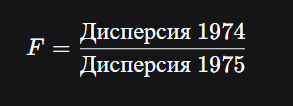
 
Пример для пары 1974 vs 1975:

Дисперсия 1974 (считаем по формуле): ≈ 244 600

Дисперсия 1975: ≈ 362 700

F = 244 600 / 362 700 = 0.6744 (именно это число вывел твой код).

🕵️ Шаг 4: Что это значит (p-value)
Если дисперсии идеально равны, то F = 1.0.
Твоё F = 0.6744 — это близко к 1 (различие всего 30%). Это незначительно.

Теперь программа смотрит: «А если бы дисперсии были на самом деле равны, какова вероятность случайно получить F = 0.6744?»
Ответ (p-value) = 0.5245.

Правило: Если p > 0.05, мы говорим: «Да, различие в 30% — это просто случайность (шум). Дисперсии равны».

In [32]:
def f_test(a, b):
    a = np.asarray(a, float)
    b = np.asarray(b, float)
    F = a.var(ddof=1) / b.var(ddof=1)
    dfn, dfd = len(a) - 1, len(b) - 1
    cdf = stats.f.cdf(F, dfn, dfd)
    p = 2 * min(cdf, 1 - cdf)
    return F, p, dfn, dfd

print("[8] Критерий Фишера: равенство дисперсий между годами")
for i in range(len(years)):
    for j in range(i + 1, len(years)):
        F, p, dfn, dfd = f_test(groups[years[i]], groups[years[j]])
        print(f"  {years[i]} vs {years[j]}: F = {F:8.4f}, df = ({dfn}, {dfd}), p = {p:.4g}  → {verdict(p)}")

[8] Критерий Фишера: равенство дисперсий между годами
  1974 vs 1975: F =   0.6744, df = (11, 11), p = 0.5245  → H0 НЕ отвергается (p>alpha)
  1974 vs 1976: F =   0.3535, df = (11, 11), p = 0.09879  → H0 НЕ отвергается (p>alpha)
  1974 vs 1977: F =   0.8026, df = (11, 11), p = 0.7218  → H0 НЕ отвергается (p>alpha)
  1974 vs 1978: F =   0.6332, df = (11, 11), p = 0.4607  → H0 НЕ отвергается (p>alpha)
  1974 vs 1979: F =   0.7470, df = (11, 11), p = 0.6369  → H0 НЕ отвергается (p>alpha)
  1975 vs 1976: F =   0.5241, df = (11, 11), p = 0.299  → H0 НЕ отвергается (p>alpha)
  1975 vs 1977: F =   1.1900, df = (11, 11), p = 0.778  → H0 НЕ отвергается (p>alpha)
  1975 vs 1978: F =   0.9388, df = (11, 11), p = 0.9185  → H0 НЕ отвергается (p>alpha)
  1975 vs 1979: F =   1.1076, df = (11, 11), p = 0.8684  → H0 НЕ отвергается (p>alpha)
  1976 vs 1977: F =   2.2705, df = (11, 11), p = 0.1896  → H0 НЕ отвергается (p>alpha)
  1976 vs 1978: F =   1.7912, df = (11, 11), p = 0.348  → H0 НЕ отвергается (

**Вывод по п.8:**
Все p-value > 0.05, следовательно H0 **не отвергается**. Дисперсии смертности между годами статистически неразличимы. F-тест чувствителен к нарушению нормальности, поэтому на практике для проверки равенства дисперсий лучше использовать тест Levene.

Что такое тест Левена?
Что проверяет: То же самое, что и Фишер — равенство дисперсий (H0: σ₁² = σ₂² = ... = σₖ²).

В чем отличие от Фишера:

Фишер сравнивает дисперсии и требует, чтобы данные были нормальными.

Левен вместо самих значений берет абсолютные отклонения от медианы (или среднего) и сравнивает их. Ему все равно, нормальные данные или нет. Он работает даже с перекошенными данными.

Как читать: p > 0.05 → дисперсии равны (H0 не отвергается). p < 0.05 → дисперсии разные.

Зачем он в лабе: Так как в trees датасет Volume не нормален, F-тест там формально врет. Левен бы показал более честный результат. В ldeaths он покажет, что смертность по годам имеет одинаковый разброс.

In [39]:
import pandas as pd
from scipy import stats

# Читаем файл напрямую (он же лежит в этой папке!)
trees = pd.read_csv("trees.csv")

# Убираем столбец rownames, если он есть
trees = trees.drop(columns=[c for c in trees.columns if c.lower().startswith("row")], errors="ignore")

print("\n[Дополнительно] Тест Левена: проверка равенства дисперсий")
print("(В отличие от F-теста, Левен устойчив к отклонениям от нормальности)")

# Тест Левена для всех трех столбцов
stat_lev, p_lev = stats.levene(trees['Girth'], trees['Height'], trees['Volume'])

print(f"\n  Глобальный тест (Girth vs Height vs Volume):")
print(f"  Levene statistic = {stat_lev:.4f}")
print(f"  p-value          = {p_lev:.4g}")

if p_lev <= 0.05:
    print(f"  Вывод: Дисперсии значимо различаются (p <= 0.05).")
    print("  Это логично: переменные измерены в разных единицах.")
else:
    print(f"  Вывод: Дисперсии статистически неразличимы (p > 0.05).")

# Попарный тест Левена (Girth vs Height)
stat_pair, p_pair = stats.levene(trees['Girth'], trees['Height'])
print(f"\n  Попарный тест (Girth vs Height):")
print(f"  Levene statistic = {stat_pair:.4f}, p-value = {p_pair:.4g}")

if p_pair <= 0.05:
    print(f"  Вывод: Дисперсии Girth и Height различаются (p <= 0.05).")
else:
    print(f"  Вывод: Дисперсии Girth и Height неразличимы (p > 0.05).")


[Дополнительно] Тест Левена: проверка равенства дисперсий
(В отличие от F-теста, Левен устойчив к отклонениям от нормальности)

  Глобальный тест (Girth vs Height vs Volume):
  Levene statistic = 13.5324
  p-value          = 7.273e-06
  Вывод: Дисперсии значимо различаются (p <= 0.05).
  Это логично: переменные измерены в разных единицах.

  Попарный тест (Girth vs Height):
  Levene statistic = 11.9745, p-value = 0.0009993
  Вывод: Дисперсии Girth и Height различаются (p <= 0.05).
